# To be completed at the Data Science Workshop and in your own time.

These set of examples we will help you get familiar with non parametric tests and correlations within a Jupyter notebook.   The questions coloured green are important practice for CA, particularly Question 5.

Before attempting these examples, please ensure you have read through [Chapter 5 Jupyter Notebook](https://github.com/itrharrison/PX4146/blob/main/Chapter5/Chapter5.ipynb) and have completed the Learning Central **Chapter 5 quiz**.

***

#  Hypothesis Testing

## <font color=#30a64d>Question</font>

In the previous week, we used the datafile [worldpopulation.txt](https://github.com/itrharrison/PX4146/blob/main/Chapter4/worldpopulation.txt) to estimate the correlation between the world population size measured over time.

1. Measure the correlation coefficient using the in built Python package for the Spearman $\rho$ statistic.

2. Measure it again but this time creating the functions to calculate $\rho$ from scratch.   You can use the in-built function to rank datasets from scipy.stats: `from scipy.stats import rankdata`.

### Answer

*Your answer here.*

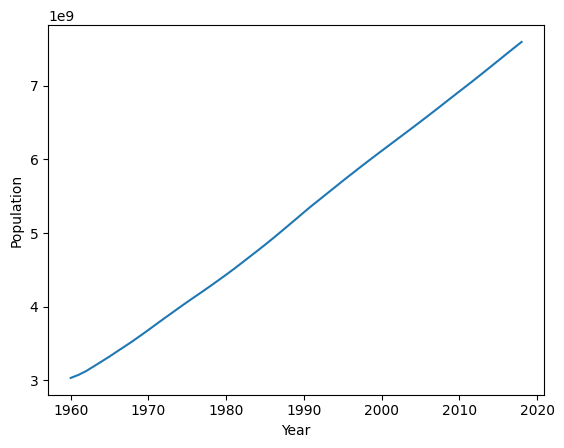

rho = 1.000, p = 0.000
rho_s = 1.000


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.stats import rankdata

# Read using whitespace as delimiter
df=np.loadtxt("worldpopulation.txt")
year = df[0]
pop = df[1]

plt.plot(year, pop)
plt.xlabel("Year")
plt.ylabel("Population")
plt.show()

spearman_r, spearman_p = spearmanr(year, pop)
print(f"rho = {spearman_r:.3f}, p = {spearman_p:.3f}")

rho_s=1-np.sum((rankdata(year)-rankdata(pop))**2)/(len(year)*(len(year)**2-1))
print(f"rho_s = {rho_s:.3f}")

***

# KS Test

## Question

Two near-by apple trees are in bloom in an otherwise empty field. One is a Whitney Crab the other is a Redwell. We want to test if bees prefer one tree to the other.

To do this we collect data. We use a stop watch to time how long a bee stays near a particular tree. We begin to time when the bee touches the tree, we stop timing when the bee is more than a metre from the tree. Unfortunately we did not get exactly the same number of bees for each tree as it started to rain.   The data is below (time is in seconds). Can we conclude anything based on our experiment?

redwell= 23.4, 30.9, 18.8, 23.0, 21.4, 1, 24.6, 23.8, 24.1, 18.7, 16.3, 20.3, 14.9, 35.4, 21.6, 21.2, 21.0, 15.0, 15.6, 24.0, 34.6, 40.9, 30.7, 24.5, 16.6, 1, 21.7, 1, 23.6, 1, 25.7, 19.3, 46.9, 23.3, 21.8, 33.3, 24.9, 24.4, 1, 19.8, 17.2, 21.5, 25.5, 23.3, 18.6, 22.0, 29.8, 33.3, 1, 21.3, 18.6, 26.8, 19.4, 21.1, 21.2, 20.5, 19.8, 26.3, 39.3, 21.4, 22.6, 1, 35.3, 7.0, 19.3, 21.3, 10.1, 20.2, 1, 36.2, 16.7, 21.1, 39.1, 19.9, 32.1, 23.1, 21.8, 30.4, 19.62, 15.5

whitney=16.5, 1, 22.6, 25.3, 23.7, 1, 23.3, 23.9, 16.2, 23.0, 21.6, 10.8, 12.2, 23.6, 10.1, 24.4, 16.4, 11.7, 17.7, 34.3, 24.3, 18.7, 27.5, 25.8, 22.5, 14.2, 21.7, 1, 31.2, 13.8, 29.7, 23.1, 26.1, 25.1, 23.4, 21.7, 24.4, 13.2, 22.1, 26.7, 22.7, 1, 18.2, 28.7, 29.1, 27.4, 22.3, 13.2, 22.5, 25.0, 1, 6.6, 23.7, 23.5, 17.3, 24.6, 27.8, 29.7, 25.3, 19.9, 18.2, 26.2, 20.4, 23.3, 26.7, 26.0, 1, 25.1, 33.1, 35.0, 25.3, 23.6, 23.2, 20.2, 24.7, 22.6, 39.1, 26.5, 22.7

### Answer

*Your answer here.*

redwell has bee time of 21.403 +/- 9.557
whitney has bee time of 21.113 +/- 8.063
stat = 0.220, p = 0.034


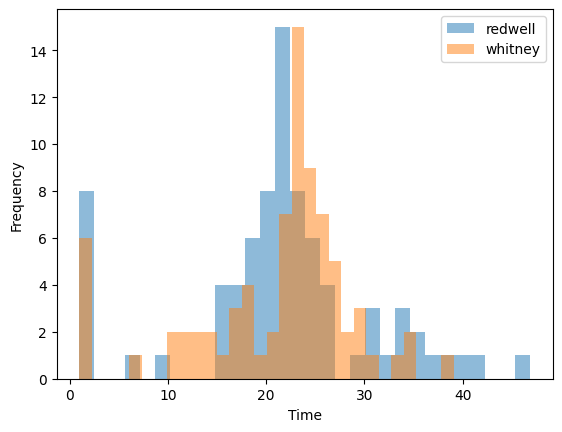

In [18]:
import numpy as np
from scipy.stats import ks_2samp

redwell = [23.4, 30.9, 18.8, 23.0, 21.4, 1, 24.6, 23.8, 24.1, 18.7, 16.3, 20.3, 14.9, 35.4, 21.6, 21.2, 21.0, 15.0, 15.6, 24.0, 34.6, 40.9, 30.7,
           24.5, 16.6, 1, 21.7, 1, 23.6, 1, 25.7, 19.3, 46.9, 23.3, 21.8, 33.3, 24.9, 24.4, 1, 19.8, 17.2, 21.5, 25.5, 23.3, 18.6, 22.0, 29.8, 33.3,
           1, 21.3, 18.6, 26.8, 19.4, 21.1, 21.2, 20.5, 19.8, 26.3, 39.3, 21.4, 22.6, 1, 35.3, 7.0, 19.3, 21.3, 10.1, 20.2, 1, 36.2, 16.7, 21.1, 39.1,
           19.9, 32.1, 23.1, 21.8, 30.4, 19.62, 15.5]
whitney = [16.5, 1, 22.6, 25.3, 23.7, 1, 23.3, 23.9, 16.2, 23.0, 21.6, 10.8, 12.2, 23.6, 10.1, 24.4, 16.4, 11.7, 17.7, 34.3, 24.3, 18.7, 27.5, 25.8,
           22.5, 14.2, 21.7, 1, 31.2, 13.8, 29.7, 23.1, 26.1, 25.1, 23.4, 21.7, 24.4, 13.2, 22.1, 26.7, 22.7, 1, 18.2, 28.7, 29.1, 27.4, 22.3, 13.2,
           22.5, 25.0, 1, 6.6, 23.7, 23.5, 17.3, 24.6, 27.8, 29.7, 25.3, 19.9, 18.2, 26.2, 20.4, 23.3, 26.7, 26.0, 1, 25.1, 33.1, 35.0, 25.3, 23.6,
           23.2, 20.2, 24.7, 22.6, 39.1, 26.5, 22.7]

mean_redwell = np.mean(redwell)
std_redwell = np.std(redwell)
mean_whitney = np.mean(whitney)
std_whitney = np.std(whitney)

print(f"redwell has bee time of {mean_redwell:.3f} +/- {std_redwell:.3f}")
print(f"whitney has bee time of {mean_whitney:.3f} +/- {std_whitney:.3f}")


stat, p = ks_2samp(redwell, whitney)
print(f"stat = {stat:.3f}, p = {p:.3f}")

plt.hist(redwell, bins=30, alpha=0.5, label='redwell')
plt.hist(whitney, bins=30, alpha=0.5, label='whitney')
plt.legend()
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.show()

***

# Chi-square test

## Question

You publish flyers for an event in three different colours and want to test whether the colour has a significant affect on whether people take them. The data is available below.  Use the $\chi^2$ test to do this, and calculate the probability of the significance of the result.

| |white | light blue | neon pink | Totals|
|---|---|---|---|---|
|Take | 32| 38 | 20| 90|
|Don't take | 8| 22 |30 | 60|
|Totals | 40|60 | 50| 150|

### Answer

*Your answer here.*

In [12]:
import numpy as np
from scipy.stats import chi2_contingency

data = np.array([[32, 38, 20], [8, 22, 30]])
stat, p, dof, expected = chi2_contingency(data)
print(f"stat = {stat:.3f}, p = {p:.5f}")

stat = 15.278, p = 0.00048


In [13]:
#expected number
E_white_taken = (40*90)/150
E_lblue_taken = (60*90)/150
E_npink_taken = (50*90)/150

E_white_nottaken = (40*60)/150
E_lblue_nottaken = (60*60)/150
E_npink_nottaken = (50*60)/150

print(f"E_white_taken = {E_white_taken:.3f}, E_lblue_taken = {E_lblue_taken:.3f}, E_npink_taken = {E_npink_taken:.3f}")
print(f"E_white_nottaken = {E_white_nottaken:.3f}, E_lblue_nottaken = {E_lblue_nottaken:.3f}, E_npink_nottaken = {E_npink_nottaken:.3f}")

#chi^2 stat
chi_square = ((32-E_white_taken)**2)/E_white_taken + ((8-E_white_nottaken)**2)/E_white_nottaken + ((38-E_lblue_taken)**2)/E_lblue_taken + ((22-E_lblue_nottaken)**2)/E_lblue_nottaken + ((20-E_npink_taken)**2)/E_npink_taken + ((30-E_npink_nottaken)**2)/E_npink_nottaken
print(f"chi_square = {chi_square:.3f}")

E_white_taken = 24.000, E_lblue_taken = 36.000, E_npink_taken = 30.000
E_white_nottaken = 16.000, E_lblue_nottaken = 24.000, E_npink_nottaken = 20.000
chi_square = 15.278


***